# Random Forest
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Distrito Centro (Rosario)

## Marco teórico

Los modelos lineales de los notebooks 01 y 02 asumen una forma **aditiva y lineal**: el efecto de cada
atributo es constante y no depende de los demás. Eso deja afuera dos cosas que en el mercado inmobiliario
pesan: las **no linealidades** (el precio por m² no crece igual en un monoambiente que en un piso grande)
y las **interacciones** (una cochera no vale lo mismo en el microcentro que en la periferia). Los modelos
basados en **árboles** capturan ambas sin que uno tenga que especificarlas de antemano.

Un **árbol de regresión** (CART) parte el espacio de predictores en regiones y predice un valor constante
en cada una (Hastie, Tibshirani & Friedman, 2009, cap. 9). Es flexible pero **inestable**: un árbol
profundo tiene poco sesgo y **mucha varianza**. El **bagging** (Breiman, 1996) promedia muchos árboles
entrenados sobre remuestreos *bootstrap*: al promediar, la varianza baja sin subir el sesgo. El **Random
Forest** (Breiman, 2001) agrega que, en cada división, cada árbol solo elige entre un **subconjunto
aleatorio de predictores**: eso **descorrelaciona** los árboles y hace que el promedio reduzca aún más la
varianza (ESL, cap. 15; ISL, cap. 8). El resultado capta **no linealidades e interacciones**, es robusto
a la escala y a outliers en las *x*, y requiere poco preprocesamiento. El costo es la **interpretabilidad**
(no hay un coeficiente por variable), que compensamos con medidas de **importancia**. Comparar este modelo
contra el hedónico es el eje de **RQ1** (Kuhn & Johnson, 2013).

## Metodología (protocolo experimental)

- **Datos y target:** matriz de modelado; target $\log(1+\text{precio\_usd})$, métricas retransformadas a USD.
- **Particionado:** mismas **particiones group-aware** que el hedónico (`GroupKFold`, 5 folds, grupo =
  `building_cluster_id`) → comparación **pareada** y sin fuga por republicaciones (Gutiérrez et al., 2026).
- **Preprocesamiento dentro del fold:** imputación + one-hot (los árboles no requieren estandarización),
  ajustado solo con el train.
- **CV anidada (sin sesgo optimista):** los hiperparámetros (`max_features`, `min_samples_leaf`) se eligen
  por CV **interna** group-aware **dentro del train de cada fold externo**. Así el fold de test no
  participa en la selección del modelo, y la métrica de test queda libre de fuga (ESL §7.10.2).
- **Reporte de entrenamiento y test:** para cada escenario mostramos R² y RMSE **en train y en test**, con
  su brecha. Es el diagnóstico de **sesgo–varianza / sobreajuste** y la base de la explicabilidad del
  modelo.
- **Escenarios incrementales S1→S4**, para ver si los árboles **aprovechan cada bloque** distinto que el
  lineal —en particular la microlocalización (S3), que el lineal casi no usaba—.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT = "#2c6e91", "#c0562b", "#3a8f5e"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5, "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
groups = df["building_cluster_id"].values
feat_cols = [c for c in df.columns if c.startswith("feat_")]

S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
escen = {"S1":[c for c in S1 if c in df.columns],
         "S2":[c for c in S1+S2 if c in df.columns],
         "S3":[c for c in S1+S2+S3 if c in df.columns],
         "S4":[c for c in S1+S2+S3 if c in df.columns]+feat_cols}
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
BIN = set(feat_cols) | {"fe_tiene_cochera","fe_expensas_informadas"}
N_TREES, SEED, N_IN = 600, 42, 3
GRID = {"m__max_features":["sqrt",0.33,0.5,0.7], "m__max_depth":[None,16,24], "m__min_samples_leaf":[1,2,5]}
print(f"Matriz: {len(df):,} avisos · {df['building_cluster_id'].nunique():,} grupos · RF({N_TREES}) · CV anidada 5×{N_IN} group-aware")

Matriz: 4,765 avisos · 1,377 grupos · RF(600) · CV anidada 5×3 group-aware


## Pipelines y esquema de evaluación

El Random Forest usa imputación + one-hot (sin escalar). Para la comparación pareada evaluamos también el
**hedónico (OLS)** con su preprocesamiento del notebook 01 (imputación + one-hot + estandarización), sobre
**las mismas particiones**. La función `nested` recorre los folds externos, tunea el RF **dentro** de cada
train y devuelve métricas de **train** y **test** (y las predicciones fuera de fold, para el análisis por
segmento).

In [2]:
def prep_rf(cols):
    cat=[c for c in cols if c in CAT]; binz=[c for c in cols if c in BIN]; num=[c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10,sparse_output=False))]), cat),
        ("bin", SimpleImputer(strategy="most_frequent"), binz),
        ("num", SimpleImputer(strategy="median"), num)], remainder="drop")

def prep_ols(cols):
    cat=[c for c in cols if c in CAT]; binz=[c for c in cols if c in BIN]; num=[c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10))]), cat),
        ("bin","passthrough",binz),
        ("num", Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]), num)], remainder="drop")

def _met(yv,pv): return r2_score(yv,pv), np.sqrt(mean_squared_error(np.expm1(yv),np.expm1(pv)))

def nested(cols):
    "CV anidada RF: tunea dentro del train de cada fold; devuelve métricas train/test y OOF."
    gkf=GroupKFold(5); tr_r2=[];te_r2=[];tr_rm=[];te_rm=[];te_mape=[]; oof=np.full(len(y),np.nan)
    for tr,te in gkf.split(df,y,groups):
        base=Pipeline([("prep",prep_rf(cols)),("m",RandomForestRegressor(n_estimators=N_TREES,random_state=SEED,n_jobs=1))])
        gs=GridSearchCV(base,GRID,cv=GroupKFold(N_IN),scoring="neg_mean_squared_error",n_jobs=-1).fit(df.iloc[tr][cols],y[tr],groups=groups[tr])
        est=gs.best_estimator_; ptr=est.predict(df.iloc[tr][cols]); pte=est.predict(df.iloc[te][cols]); oof[te]=pte
        a,b=_met(y[tr],ptr); c,d=_met(y[te],pte); tr_r2.append(a);tr_rm.append(b);te_r2.append(c);te_rm.append(d)
        ytu,ypu=np.expm1(y[te]),np.expm1(pte); te_mape.append(np.mean(np.abs((ytu-ypu)/ytu))*100)
    return dict(R2_train=np.mean(tr_r2),R2_test=np.mean(te_r2),R2_test_sd=np.std(te_r2),
                RMSE_train=np.mean(tr_rm),RMSE_test=np.mean(te_rm),MAPE_test=np.mean(te_mape),
                brecha=np.mean(tr_r2)-np.mean(te_r2)), oof

def ols_train_test(cols):
    "OLS (sin hiperparámetros): train/test por fold y OOF."
    gkf=GroupKFold(5); tr_r2=[];te_r2=[];tr_rm=[];te_rm=[];te_mape=[]; oof=np.full(len(y),np.nan)
    for tr,te in gkf.split(df,y,groups):
        est=Pipeline([("prep",prep_ols(cols)),("m",LinearRegression())]).fit(df.iloc[tr][cols],y[tr])
        ptr=est.predict(df.iloc[tr][cols]); pte=est.predict(df.iloc[te][cols]); oof[te]=pte
        a,b=_met(y[tr],ptr); c,d=_met(y[te],pte); tr_r2.append(a);tr_rm.append(b);te_r2.append(c);te_rm.append(d)
        ytu,ypu=np.expm1(y[te]),np.expm1(pte); te_mape.append(np.mean(np.abs((ytu-ypu)/ytu))*100)
    return dict(R2_train=np.mean(tr_r2),R2_test=np.mean(te_r2),RMSE_train=np.mean(tr_rm),
                RMSE_test=np.mean(te_rm),MAPE_test=np.mean(te_mape),brecha=np.mean(tr_r2)-np.mean(te_r2)), oof
print("Pipelines y utilitarios definidos.")

Pipelines y utilitarios definidos.


## 1. Entrenamiento vs. test por escenario (diagnóstico de sobreajuste)

Para cada escenario reportamos R² y RMSE **en entrenamiento y en test**, y la **brecha** entre ambos. La
brecha es la lupa del sesgo–varianza: si train ≈ test, el modelo no sobreajusta; si train ≫ test, hay
memorización. Como la CV es **anidada**, el test está libre del sesgo por selección de hiperparámetros.

,features,R2_train,R2_test,brecha_R2,RMSE_train,RMSE_test,MAPE_test
S1,19.0,0.941,0.863,0.079,28577.0,46345.0,20.1
S2,22.0,0.975,0.879,0.096,19225.0,44222.0,18.5
S3,26.0,0.982,0.882,0.100,17225.0,43848.0,18.4
S4,45.0,0.986,0.890,0.096,15686.0,42998.0,17.7


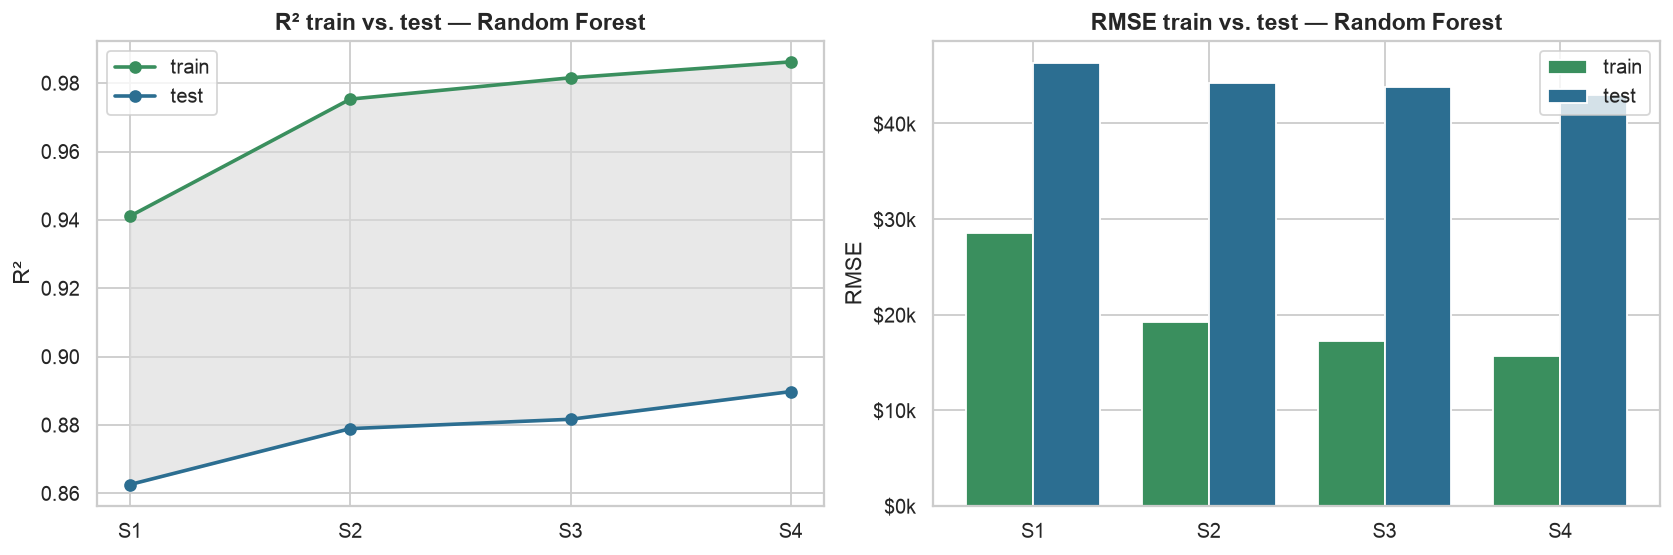

In [3]:
rf_res, rf_oof = {}, {}
for k,cols in escen.items():
    rf_res[k], rf_oof[k] = nested(cols)
tt = pd.DataFrame({k:{"features":len(escen[k]),"R2_train":rf_res[k]["R2_train"],"R2_test":rf_res[k]["R2_test"],
                      "brecha_R2":rf_res[k]["brecha"],"RMSE_train":rf_res[k]["RMSE_train"],
                      "RMSE_test":rf_res[k]["RMSE_test"],"MAPE_test":rf_res[k]["MAPE_test"]} for k in escen}).T
display(tt.round({"features":0,"R2_train":3,"R2_test":3,"brecha_R2":3,"RMSE_train":0,"RMSE_test":0,"MAPE_test":1}))

# se guarda la tabla para la comparación de los tres modelos en el notebook de LightGBM
(ROOT/"reports"/"tables"/"modelado").mkdir(parents=True, exist_ok=True)
tt.rename(columns={"features":"n_features"}).rename_axis("escenario").to_csv(ROOT/"reports"/"tables"/"modelado"/"random_forest_s1_s4.csv")

fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(escen))
axs[0].plot(x,tt["R2_train"],"o-",color=ACCENT,lw=2,label="train")
axs[0].plot(x,tt["R2_test"],"o-",color=PAL,lw=2,label="test")
axs[0].fill_between(x,tt["R2_test"],tt["R2_train"],color="0.85",alpha=.6)
axs[0].set(title="R² train vs. test — Random Forest",ylabel="R²",xticks=x); axs[0].set_xticklabels(list(escen)); axs[0].legend()
axs[1].bar(x-0.19,tt["RMSE_train"],0.38,color=ACCENT,label="train")
axs[1].bar(x+0.19,tt["RMSE_test"],0.38,color=PAL,label="test")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="RMSE train vs. test — Random Forest",ylabel="RMSE",xticks=x); axs[1].set_xticklabels(list(escen)); axs[1].legend()
plt.show()

**Lectura.** El desempeño en test aumenta al incorporar información: el R² pasa de 0,863 (S1) a
0,890 (S4) y el RMSE de ~USD 46k a ~USD 43k, con el incremento más marcado en el bloque de
**localización (S2)** y un aporte adicional del **texto (S4)**; la **microlocalización (S3)** muestra un
aporte menor. En paralelo se observa una **brecha train–test** considerable —el R² de entrenamiento se
ubica entre ~0,94 y ~0,99—, un comportamiento habitual en Random Forest, donde cada árbol ajusta de cerca
el conjunto de entrenamiento. Esta brecha no invalidaría la lectura del test —que es la métrica de
interés—, pero conviene tenerla presente; tiende a ampliarse a medida que se agregan predictores (de
~0,08 en S1 a ~0,10 en S3–S4), lo que sería consistente con una mayor capacidad de ajuste. Al tratarse de
una **CV anidada**, estos valores de test no estarían inflados por la selección de hiperparámetros.

## 2. Comparación pareada: Random Forest vs. hedónico (RQ1)

Evaluamos el **hedónico (OLS)** sobre las mismas particiones —también con su train y test— y lo ponemos
lado a lado con el RF. Es la comparación central de la tesis.

,RF_R2_test,OLS_R2_test,RF_RMSE_test,OLS_RMSE_test,RF_brecha,OLS_brecha,ΔRMSE_%
S1,0.863,0.820,46345.0,86121.0,0.079,0.007,46.2
S2,0.879,0.847,44222.0,73285.0,0.096,0.007,39.7
S3,0.882,0.849,43848.0,72649.0,0.100,0.009,39.6
S4,0.890,0.866,42998.0,64571.0,0.096,0.009,33.4


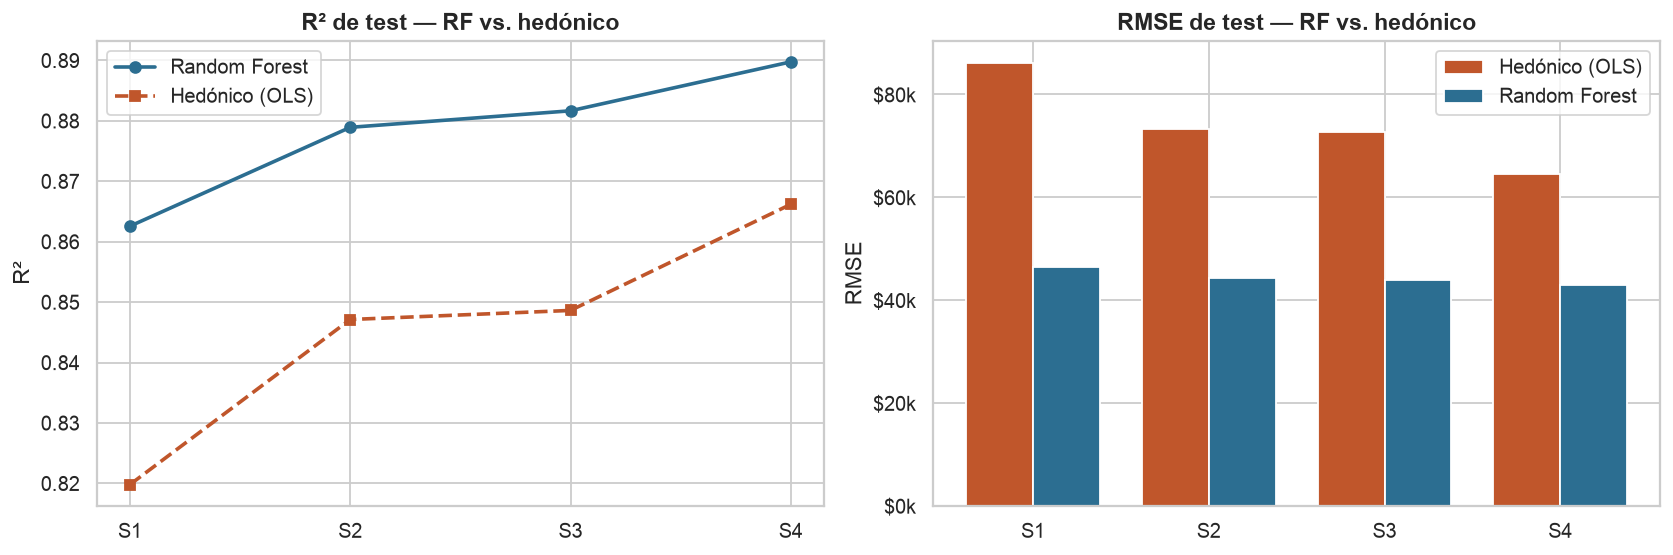

In [4]:
ols_res, ols_oof = {}, {}
for k,cols in escen.items():
    ols_res[k], ols_oof[k] = ols_train_test(cols)

comp = pd.DataFrame({
    "RF_R2_test":[rf_res[k]["R2_test"] for k in escen], "OLS_R2_test":[ols_res[k]["R2_test"] for k in escen],
    "RF_RMSE_test":[rf_res[k]["RMSE_test"] for k in escen], "OLS_RMSE_test":[ols_res[k]["RMSE_test"] for k in escen],
    "RF_brecha":[rf_res[k]["brecha"] for k in escen], "OLS_brecha":[ols_res[k]["brecha"] for k in escen],
}, index=list(escen))
comp["ΔRMSE_%"]=(comp["OLS_RMSE_test"]-comp["RF_RMSE_test"])/comp["OLS_RMSE_test"]*100
display(comp.round({"RF_R2_test":3,"OLS_R2_test":3,"RF_RMSE_test":0,"OLS_RMSE_test":0,"RF_brecha":3,"OLS_brecha":3,"ΔRMSE_%":1}))

fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(escen)); w=.38
axs[0].plot(x,comp["RF_R2_test"],"o-",color=PAL,lw=2,label="Random Forest")
axs[0].plot(x,comp["OLS_R2_test"],"s--",color=PAL2,lw=2,label="Hedónico (OLS)")
axs[0].set(title="R² de test — RF vs. hedónico",ylabel="R²",xticks=x); axs[0].set_xticklabels(list(escen)); axs[0].legend()
axs[1].bar(x-w/2,comp["OLS_RMSE_test"],w,color=PAL2,label="Hedónico (OLS)")
axs[1].bar(x+w/2,comp["RF_RMSE_test"],w,color=PAL,label="Random Forest")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="RMSE de test — RF vs. hedónico",ylabel="RMSE",xticks=x); axs[1].set_xticklabels(list(escen)); axs[1].legend()
plt.show()

**Lectura.** Las diferencias en **test** son consistentes en todos los escenarios y favorables al
Random Forest. En el escenario completo, el RF registra un RMSE de test de ~USD 43k frente a ~USD 65k del
hedónico (una reducción del orden del **33%**), un MAPE algo menor (~17,7% vs ~19,9%) y un R² mayor
(0,890 vs 0,866). Un aspecto para destacar es que el RF con **solo atributos estructurales (S1)** alcanza
en R² y MAPE valores comparables a los del hedónico completo (S4) y un RMSE marcadamente menor; esto
sugeriría que buena parte de la señal no aprovechada por el modelo lineal residiría en la **forma** de la
relación (no linealidades e interacciones) más que en variables faltantes. La columna de **brechas**
aporta un matiz: el hedónico presenta una brecha train–test muy pequeña (~0,01), compatible con la
ausencia de sobreajuste apreciable y con un límite asociado al **sesgo** del modelo; el RF exhibe una
brecha mayor (~0,10), compatible con una mayor **capacidad de ajuste**. Como referencia, la
regularización (notebook 02, R² ~0,87 / RMSE ~USD 63k en S4) no alcanzaba estos niveles de test, lo que
sería consistente con que la limitación del modelo lineal provendría de su **forma funcional** más que de
sobreajuste.

## 3. ¿Dónde gana el Random Forest?

El promedio esconde *dónde* mejora. Comparamos el error porcentual (test, escenario S4) por **rango de
precio**, que es donde el hedónico sufría más.

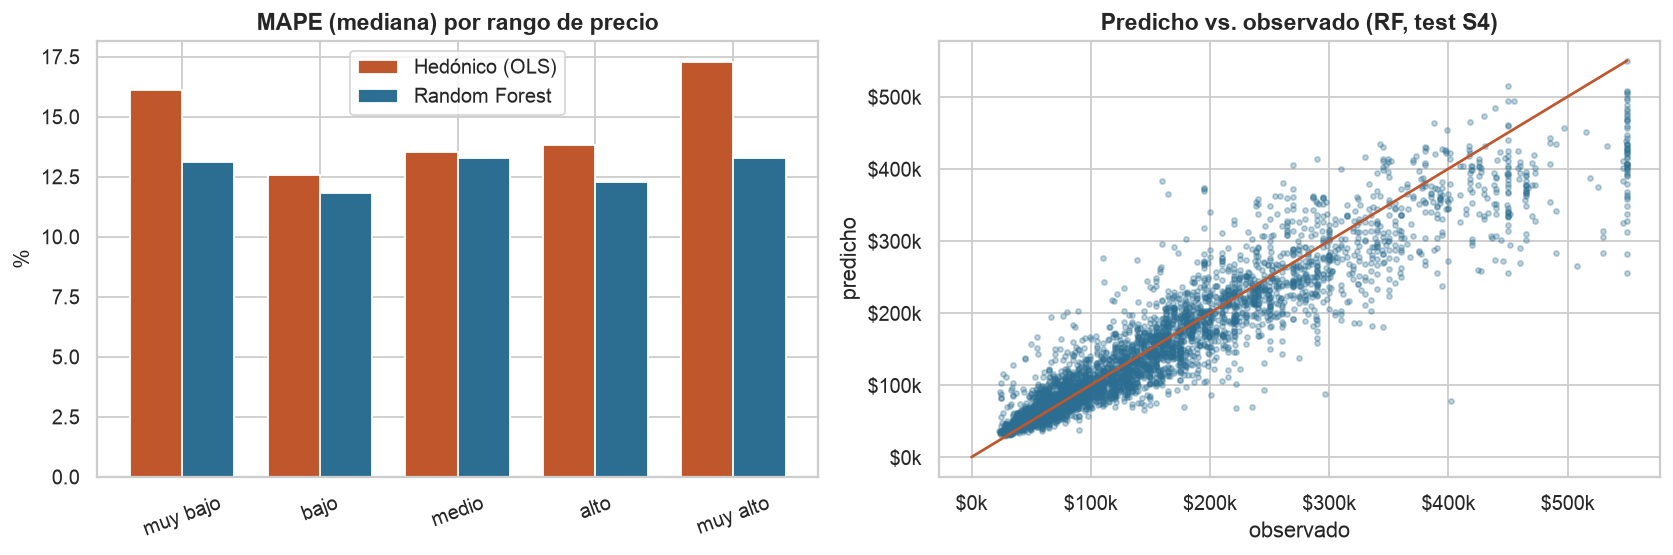

In [5]:
ytu=np.expm1(y)
def ape(o): return np.abs((ytu-np.expm1(o))/ytu)*100
d=pd.DataFrame({"precio":ytu,"ape_rf":ape(rf_oof["S4"]),"ape_ols":ape(ols_oof["S4"])})
d["q"]=pd.qcut(d["precio"],5,labels=["muy bajo","bajo","medio","alto","muy alto"])
g=d.groupby("q")[["ape_ols","ape_rf"]].median()
fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(g)); w=.38
axs[0].bar(x-w/2,g["ape_ols"],w,color=PAL2,label="Hedónico (OLS)")
axs[0].bar(x+w/2,g["ape_rf"],w,color=PAL,label="Random Forest")
axs[0].set(title="MAPE (mediana) por rango de precio",ylabel="%",xticks=x); axs[0].set_xticklabels(g.index,rotation=20); axs[0].legend()
lim=np.percentile(ytu,99)
axs[1].scatter(ytu.clip(0,lim),np.expm1(rf_oof["S4"]).clip(0,lim),s=8,alpha=.3,color=PAL)
axs[1].plot([0,lim],[0,lim],color=PAL2,lw=1.5)
axs[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k")); axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="Predicho vs. observado (RF, test S4)",xlabel="observado",ylabel="predicho")
plt.show()

**Lectura.** El RF muestra menor error en todos los rangos, con diferencias más marcadas en los
**extremos de precio** —propiedades de menor y mayor valor—, que era donde el modelo lineal presentaba
mayor dificultad (su patrón en U del notebook 01). La nube de predicho vs. observado del RF se aproxima
más a la diagonal y muestra menor dispersión en los precios altos, un comportamiento compatible con la
capacidad de los árboles de ajustar por tramos y acomodar mejor la heterogeneidad de las colas.

## 4. Importancia de variables

Dos medidas complementarias: la **importancia por impureza (MDI)**, rápida pero **sesgada** hacia
variables continuas y de alta cardinalidad (Strobl et al., 2007), y la **importancia por permutación**,
más fiable, que usamos para ordenar. Ajustamos el modelo final sobre S4 (hiperparámetros por CV
group-aware).

Hiperparámetros del modelo final: {'m__max_depth': 16, 'm__max_features': 0.33, 'm__min_samples_leaf': 1}


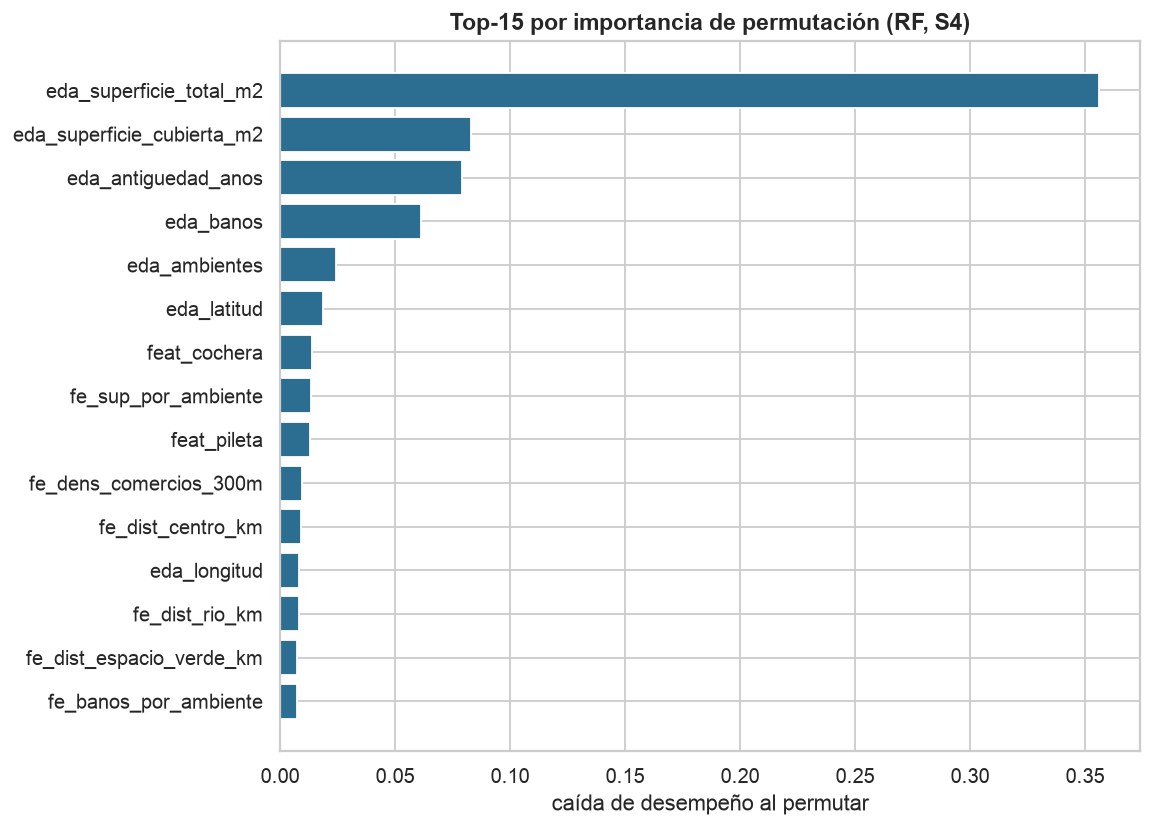

,variable,MDI,permutacion
0,eda_superficie_total_m2,0.3279,0.3561
1,eda_superficie_cubierta_m2,0.1661,0.0829
2,eda_antiguedad_anos,0.0479,0.0789
3,eda_banos,0.1515,0.0611
4,eda_ambientes,0.0573,0.0244
5,eda_latitud,0.0168,0.0187
6,feat_cochera,0.0220,0.0137
7,fe_sup_por_ambiente,0.0230,0.0133
8,feat_pileta,0.0139,0.0128
9,fe_dens_comercios_300m,0.0102,0.0093


In [6]:
base=Pipeline([("prep",prep_rf(escen["S4"])),("m",RandomForestRegressor(n_estimators=N_TREES,random_state=SEED,n_jobs=1))])
gs=GridSearchCV(base,GRID,cv=GroupKFold(5),scoring="neg_mean_squared_error",n_jobs=-1).fit(df[escen["S4"]],y,groups=groups)
final=gs.best_estimator_; print("Hiperparámetros del modelo final:",gs.best_params_)
names=[n.split("__",1)[-1] for n in final.named_steps["prep"].get_feature_names_out()]
Xt=final.named_steps["prep"].transform(df[escen["S4"]])
perm=permutation_importance(final.named_steps["m"],Xt,y,n_repeats=5,random_state=SEED,n_jobs=-1)
imp=pd.DataFrame({"variable":names,"MDI":final.named_steps["m"].feature_importances_,
                  "permutacion":perm.importances_mean}).sort_values("permutacion",ascending=False)
top=imp.head(15)
fig,ax=plt.subplots(figsize=(9,6.5))
ax.barh(top["variable"][::-1],top["permutacion"][::-1],color=PAL)
ax.set(title="Top-15 por importancia de permutación (RF, S4)",xlabel="caída de desempeño al permutar")
plt.show()
display(imp.head(12).round(4).reset_index(drop=True))

**Lectura.** El ordenamiento resulta coherente con el del hedónico y el del Lasso: la **superficie**
aparece como el predictor de mayor peso, seguida por **superficie cubierta**, **antigüedad**, **baños** y
**ambientes**, con la **latitud** y algunos atributos de texto (cochera, pileta) en posiciones
intermedias. Esta convergencia entre enfoques distintos —coeficientes del OLS, encogimiento del Lasso e
importancia del RF— aportaría respaldo a la interpretación sustantiva. Los predictores de
**microlocalización** presentan importancia baja, en línea con su aporte acotado en los distintos
modelos. Conviene recordar el sesgo conocido del MDI hacia variables continuas (Strobl et al., 2007) —se
observa que infla superficie cubierta y baños respecto de la permutación—; por eso el ordenamiento se basa
en la permutación.

## 5. Conclusiones

- **RQ1.** En test, el desempeño ordena los modelos como **hedónico < Random Forest**. En el escenario
  completo, el RF reduce el RMSE de ~USD 65k a ~USD 43k (del orden del **33%**), con mejoras también en
  MAPE (~19,9% → ~17,7%) y R² (0,866 → 0,890), sobre las **mismas particiones** y con **CV anidada**. La
  regularización no alcanzaba estos niveles, lo que sería consistente con que la limitación del modelo
  lineal provendría de su **forma funcional** más que de sobreajuste.
- **Sesgo–varianza (brecha train–test).** El hedónico presenta una brecha muy pequeña (~0,01), compatible
  con la ausencia de sobreajuste apreciable y con un techo asociado al **sesgo**; el RF exhibe una brecha
  mayor (~0,10), compatible con una mayor **capacidad de ajuste**. Ambos comportamientos ilustrarían las
  dos caras del compromiso, con mejor desempeño de test para el modelo flexible.
- **Origen de la mejora.** El RF con solo estructurales (S1) alcanza valores comparables al hedónico
  completo en R² y MAPE, con menor RMSE, lo que sugeriría que la ganancia se asociaría principalmente a
  las **no linealidades e interacciones** más que a variables adicionales. El aporte incremental se
  concentra en **localización** y **texto**; la **microlocalización (S3)** muestra un aporte menor.
- **Robustez.** Ampliar la búsqueda (600 árboles, 36 combinaciones) no modificó de forma apreciable el
  desempeño respecto de una configuración más acotada, lo que sugeriría que el modelo se encontraría
  próximo a su techo en este problema. La búsqueda seleccionó una profundidad máxima acotada
  (`max_depth=16`), asociada a una brecha algo menor sin costo en test.
- **Dónde.** La ventaja frente al lineal tiende a ampliarse en los **extremos de precio**.
- **Interpretabilidad.** La **importancia por permutación** reconstruye una jerarquía coherente con OLS y
  Lasso; la interpretación local se abordará con **SHAP** (RQ5).
- **Próximo paso.** El **gradient boosting** (LightGBM) podría aportar un desempeño algo superior; se
  evalúa a continuación sobre las mismas particiones, antes del diagnóstico espacial (RQ3–RQ4) y la
  interpretabilidad (RQ5).

## Referencias

**Libros**

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), cap. 9 y 15. Springer.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2ª ed.), cap. 8. Springer.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer. — árboles, ensembles, comparación y sobreajuste.
- Molnar, C. (2022). *Interpretable Machine Learning* (2ª ed.). — importancia por permutación.

**Artículos**

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140.
- Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures. *BMC Bioinformatics, 8*, 25.
- Gutiérrez et al. (2026); Tapia et al. (2025); Gyger et al. (2026) — antecedentes AVM y ventajas del ML por segmentos.